# Exploración de datos — Automotive Vehicles Engine Health Dataset

Fase 1 de CRISP-ML(Q) (*Business & Data Understanding*): verificación del esquema, valores faltantes, duplicados, balance de clases, distribuciones, valores atípicos y relación de cada variable con la etiqueta.

Este análisis es descriptivo: no se entrena ningún modelo y no se separa todavía el conjunto de prueba.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

def raiz_proyecto():
    """Ubica la carpeta raíz del proyecto (la que contiene data/) sin depender de dónde se ejecute el notebook."""
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "data").is_dir() and (carpeta / "notebooks").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la carpeta raíz del proyecto (con data/ y notebooks/).")

RAIZ = raiz_proyecto()
RUTA_DATOS = RAIZ / "data" / "engine_data.csv"
RUTA_FIGURAS = RAIZ / "experiments" / "eda"
print("Datos:", RUTA_DATOS)
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

Datos: c:\Users\herre\Downloads\agente-diagnostico-motores\data\engine_data.csv


## 1. Carga y esquema

In [4]:
df = pd.read_csv(RUTA_DATOS)
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (19535, 7)


,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.494,11.791,3.179,84.144,81.632,1
1,876,2.942,16.194,2.465,77.641,82.446,0
2,520,2.962,6.553,1.064,77.752,79.646,1
3,473,3.708,19.510,3.727,74.130,71.775,1
4,619,5.673,15.739,2.052,78.397,87.000,0


In [5]:
df.dtypes

Engine rpm            int64
Lub oil pressure    float64
Fuel pressure       float64
Coolant pressure    float64
lub oil temp        float64
Coolant temp        float64
Engine Condition      int64
dtype: object

Para trabajar con nombres cortos y uniformes se renombran las columnas.

In [6]:
df = df.rename(columns={
    "Engine rpm": "rpm",
    "Lub oil pressure": "presion_aceite",
    "Fuel pressure": "presion_combustible",
    "Coolant pressure": "presion_refrigerante",
    "lub oil temp": "temp_aceite",
    "Coolant temp": "temp_refrigerante",
    "Engine Condition": "condicion",
})
VARIABLES = ["rpm", "presion_aceite", "presion_combustible",
             "presion_refrigerante", "temp_aceite", "temp_refrigerante"]
OBJETIVO = "condicion"
df.columns.tolist()

['rpm',
 'presion_aceite',
 'presion_combustible',
 'presion_refrigerante',
 'temp_aceite',
 'temp_refrigerante',
 'condicion']

## 2. Valores faltantes y duplicados

In [7]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores faltantes por columna:
rpm                     0
presion_aceite          0
presion_combustible     0
presion_refrigerante    0
temp_aceite             0
temp_refrigerante       0
condicion               0
dtype: int64

Filas duplicadas: 0


## 3. Balance de clases

In [8]:
conteo = df[OBJETIVO].value_counts().sort_index()
porcentaje = df[OBJETIVO].value_counts(normalize=True).sort_index() * 100
balance = pd.DataFrame({"registros": conteo, "porcentaje": porcentaje})
balance.index = ["0 = normal", "1 = defectuoso"]
balance

,registros,porcentaje
0 = normal,7218,36.949
1 = defectuoso,12317,63.051


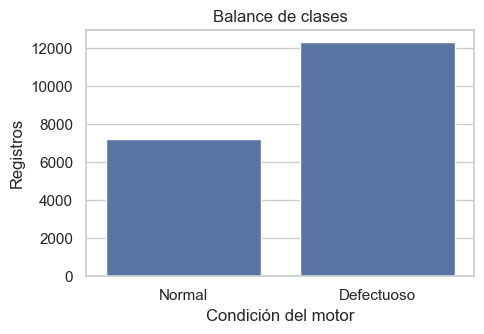

In [9]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x=df[OBJETIVO].map({0: "Normal", 1: "Defectuoso"}), ax=ax,
              order=["Normal", "Defectuoso"], color="#4C72B0")
ax.set_xlabel("Condición del motor")
ax.set_ylabel("Registros")
ax.set_title("Balance de clases")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "balance_clases.png", dpi=150)
plt.show()

Un clasificador que siempre responda «defectuoso» acierta en el 63 % de los casos. Por eso la exactitud (*accuracy*) no basta para evaluar los modelos y se usan F1-macro, AUC y el recall de la clase defectuosa.

## 4. Estadísticas descriptivas

In [10]:
df[VARIABLES].describe().T

,count,mean,std,min,25%,50%,75%,max
rpm,19535.000,791.239,267.611,61.000,593.000,746.000,934.000,2239.000
presion_aceite,19535.000,3.304,1.022,0.003,2.519,3.162,4.055,7.266
presion_combustible,19535.000,6.656,2.761,0.003,4.917,6.202,7.745,21.138
presion_refrigerante,19535.000,2.335,1.036,0.002,1.600,2.167,2.849,7.479
temp_aceite,19535.000,77.643,3.111,71.322,75.726,76.817,78.072,89.581
temp_refrigerante,19535.000,78.427,6.207,61.673,73.895,78.347,82.915,195.528


## 5. Distribuciones por clase

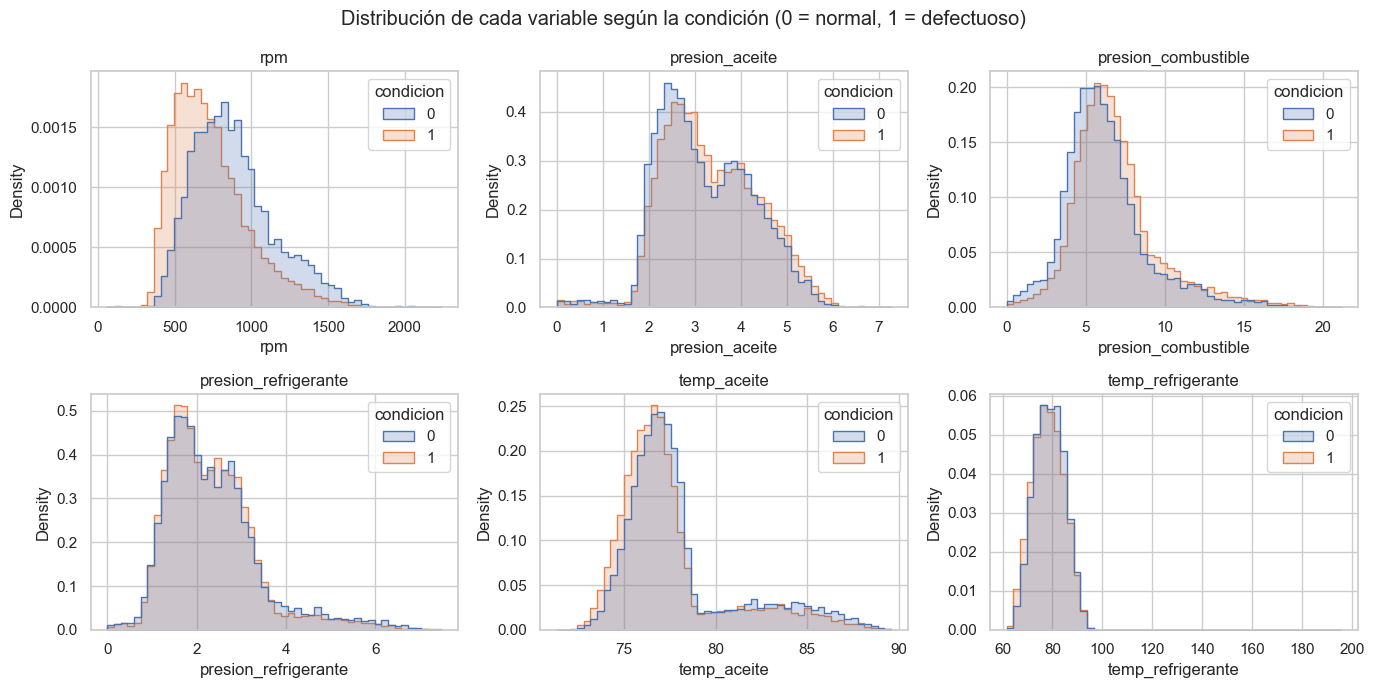

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, var in zip(axes.ravel(), VARIABLES):
    sns.histplot(data=df, x=var, hue=OBJETIVO, bins=50, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_title(var)
fig.suptitle("Distribución de cada variable según la condición (0 = normal, 1 = defectuoso)")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "distribuciones_por_clase.png", dpi=150)
plt.show()

In [12]:
medias = df.groupby(OBJETIVO)[VARIABLES].mean().T
medias.columns = ["media_normal", "media_defectuoso"]
medias["diferencia_relativa_%"] = (medias["media_defectuoso"] - medias["media_normal"]) / medias["media_normal"] * 100
medias

,media_normal,media_defectuoso,diferencia_relativa_%
rpm,884.995,736.297,-16.802
presion_aceite,3.222,3.351,4.000
presion_combustible,6.236,6.901,10.664
presion_refrigerante,2.368,2.316,-2.181
temp_aceite,78.024,77.420,-0.773
temp_refrigerante,78.803,78.207,-0.756


Solo las RPM muestran una diferencia marcada entre clases: los motores defectuosos tienen, en promedio, menos RPM. En las demás variables las distribuciones de ambas clases casi se superponen, lo que anticipa que la clasificación será difícil.

## 6. Correlación de Pearson

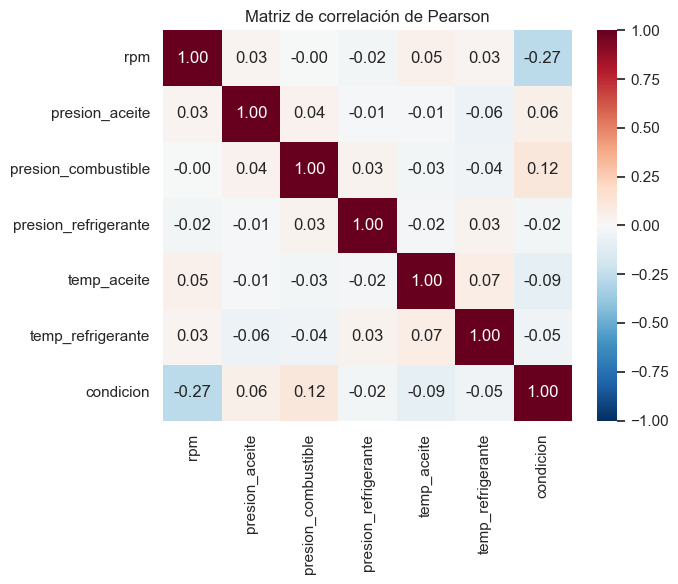

In [13]:
corr = df[VARIABLES + [OBJETIVO]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de correlación de Pearson")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "correlacion_pearson.png", dpi=150)
plt.show()

In [14]:
corr[OBJETIVO].drop(OBJETIVO).sort_values(key=np.abs, ascending=False)

rpm                    -0.268
presion_combustible     0.116
temp_aceite            -0.094
presion_aceite          0.061
temp_refrigerante      -0.046
presion_refrigerante   -0.024
Name: condicion, dtype: float64

Las correlaciones lineales con la etiqueta son débiles (la mayor es la de las RPM, negativa). Entre las variables de entrada tampoco hay correlaciones fuertes, así que no hay redundancia que obligue a eliminar columnas.

## 7. Valores atípicos

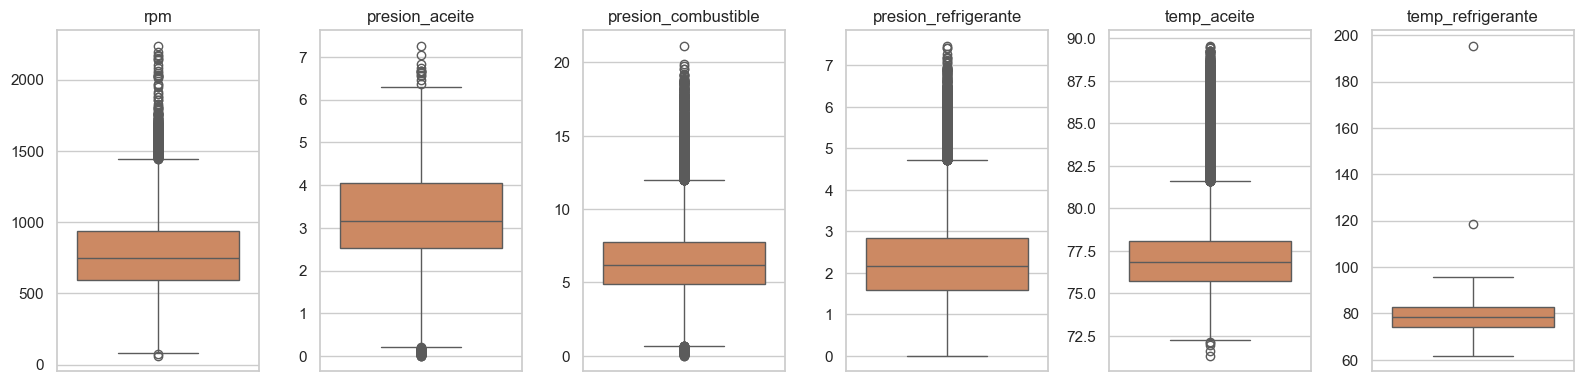

In [15]:
fig, axes = plt.subplots(1, 6, figsize=(16, 4))
for ax, var in zip(axes, VARIABLES):
    sns.boxplot(y=df[var], ax=ax, color="#DD8452")
    ax.set_title(var)
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "boxplots.png", dpi=150)
plt.show()

In [16]:
def resumen_atipicos(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series({
        "minimo": serie.min(),
        "percentil_1": serie.quantile(0.01),
        "percentil_99": serie.quantile(0.99),
        "maximo": serie.max(),
        "atipicos_IQR": ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum(),
    })

df[VARIABLES].apply(resumen_atipicos).T

,minimo,percentil_1,percentil_99,maximo,atipicos_IQR
rpm,61.000,380.000,1565.000,2239.000,464.000
presion_aceite,0.003,0.858,5.597,7.266,66.000
presion_combustible,0.003,1.380,16.130,21.138,1135.000
presion_refrigerante,0.002,0.730,5.945,7.479,785.000
temp_aceite,71.322,73.413,87.370,89.581,2617.000
temp_refrigerante,61.673,65.740,91.783,195.528,2.000


In [17]:
print("Presiones casi nulas (<= 0.05):")
for var in ["presion_aceite", "presion_combustible", "presion_refrigerante"]:
    print(f"  {var}: {(df[var] <= 0.05).sum()} registros")
print("Temperatura de refrigerante > 100:", (df["temp_refrigerante"] > 100).sum(), "registros")
df[df["temp_refrigerante"] > 100]

Presiones casi nulas (<= 0.05):
  presion_aceite: 14 registros
  presion_combustible: 6 registros
  presion_refrigerante: 9 registros
Temperatura de refrigerante > 100: 2 registros


,rpm,presion_aceite,presion_combustible,presion_refrigerante,temp_aceite,temp_refrigerante,condicion
2423,455,2.011,7.806,1.620,76.519,195.528,1
15123,760,4.908,2.595,1.748,77.873,118.372,0


La regla del rango intercuartílico (IQR) marca bastantes registros, sobre todo en temperatura de aceite y presión de combustible. Esto se debe a que esas distribuciones tienen una cola larga hacia valores altos, no a errores de medición. Los valores físicamente sospechosos son muy pocos: presiones casi nulas en menos de 15 registros por variable y 2 registros con temperatura de refrigerante superior a 100 °C (195,5 °C y 118,4 °C; el segundo está etiquetado como normal). Representan menos del 0,2 % de los datos. Siguiendo la propuesta, no se eliminan de forma indiscriminada; se conservan y se revisarán en el análisis de errores.

## 8. Condición del motor por terciles de RPM

Los terciles de RPM son los subgrupos definidos en la propuesta para medir la brecha de desempeño entre grupos.

In [18]:
df["tercil_rpm"] = pd.qcut(df["rpm"], 3, labels=["bajas", "medias", "altas"])
tabla = df.groupby("tercil_rpm", observed=True).agg(
    rango_rpm=("rpm", lambda s: f"{s.min()}–{s.max()}"),
    registros=(OBJETIVO, "size"),
    porcentaje_defectuoso=(OBJETIVO, lambda s: s.mean() * 100),
)
tabla

,rango_rpm,registros,porcentaje_defectuoso
tercil_rpm,,,
bajas,61–643,6525,79.326
medias,644–863,6501,61.683
altas,864–2239,6509,48.103


La proporción de motores defectuosos cambia mucho entre terciles (de cerca del 79 % en RPM bajas a cerca del 48 % en RPM altas). Es probable que el desempeño del modelo también varíe entre subgrupos, por lo que la métrica de brecha entre subgrupos de la propuesta es relevante.

## 9. Conclusiones de la exploración

1. El conjunto tiene 19.535 registros, 6 variables numéricas, sin valores faltantes ni duplicados.
2. Hay desbalance moderado: 63 % defectuosos y 37 % normales. Se usará partición estratificada y métricas que no dependan solo de la exactitud.
3. Las RPM son la variable con mayor relación con la etiqueta; las demás aportan poca separación individual. La tarea es difícil.
4. Los valores físicamente sospechosos son muy pocos y se conservan; los atípicos según IQR reflejan colas largas de las distribuciones.
5. Las variables tienen escalas muy distintas (RPM en cientos, presiones en unidades), así que la regresión logística necesita estandarización ajustada solo con el conjunto de entrenamiento.